# JOAN CAMILO GALVIS BARRANCO
### Preparación de Datos

In [66]:
!pip install ydata_profiling
from ydata_profiling import ProfileReport

In [67]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme("paper", style="whitegrid")

In [68]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [69]:
import numpy as np

In [70]:
#Carga inicial del set de datos
#df = pd.read_csv(r"/content/Saber_11°_2020-2_20261106.csv")
#df.to_parquet("saber_11_2020_2.parquet")

In [71]:
#Debido a la cantidad de registros se transformo el csv a parquet para mejorar el rendimiento
df = pd.read_parquet(r"/content/drive/MyDrive/PROYECTO ICFES/saber_11_2020_2.parquet")
df.shape

(504872, 81)

### 1. Integración de datos

Los datos provienen directamente de los datos ofrecidos por el ICFES, los cuales vienen en una sola tabla. Razón por la cual en esta etapa de la preparación de los datos se realizarán verificaciones de calidad de los datos.

In [72]:
print("Dimenciones del set de datos".center(50, "="))
print(f"Registros: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")
print(f"Cantidad total de datos: {df.size}\n")

print("Valores nulos".center(50, "="))
nulos = df.isna().sum().sum()
print(f"Cantidad preeliminar de nulos: {nulos}")
print(f"Porcentaje de Nulos: {nulos/df.size*100:.2f} %\n")

print("Valores Unicos".center(50, "="))
print(f"Cantidad de registros duplicados: {df.duplicated().sum().sum()}")
unicos = df.nunique().sum()
print(f"Cantidad de valores unicos: {unicos}")
print(f"Porcentaje de valores unicos: {unicos/df.size*100:.2f} %")

===========Dimenciones del set de datos===========
Registros: 504872
Columnas: 81
Cantidad total de datos: 40894632

==================Valores nulos===================
Cantidad preeliminar de nulos: 519164
Porcentaje de Nulos: 1.27 %

==================Valores Unicos==================
Cantidad de registros duplicados: 0
Cantidad de valores unicos: 1030923
Porcentaje de valores unicos: 2.52 %


In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 504872 entries, 0 to 504871
Data columns (total 81 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   ESTU_TIPODOCUMENTO             504872 non-null  object 
 1   ESTU_NACIONALIDAD              504872 non-null  object 
 2   ESTU_GENERO                    504864 non-null  object 
 3   ESTU_FECHANACIMIENTO           504872 non-null  object 
 4   PERIODO                        504872 non-null  int64  
 5   ESTU_CONSECUTIVO               504872 non-null  object 
 6   ESTU_ESTUDIANTE                504872 non-null  object 
 7   ESTU_PAIS_RESIDE               504872 non-null  object 
 8   ESTU_TIENEETNIA                501879 non-null  object 
 9   ESTU_DEPTO_RESIDE              504870 non-null  object 
 10  ESTU_COD_RESIDE_DEPTO          504870 non-null  float64
 11  ESTU_MCPIO_RESIDE              504870 non-null  object 
 12  ESTU_COD_RESIDE_MCPIO         

In [74]:
df = df[df['PUNT_GLOBAL'] != 0]
df = df[df['ESTU_ESTADOINVESTIGACION'] == "PUBLICAR"]

En esta fase de integración podemos destacar un alto volumen de datos provinientes de una unica fuente. Presenta 81 atributos de los cuales una gran parte no són de utilidad para el aprendizaje del modelo. Por otra parte, la cantidad de valores nulos y duplicados es bastante baja.

Es importante destacar que al menos 52 atributos son de tipo categorico, sin contar la existencia de variables de naturaleza categorica que hayan sido codificadas.

Por ultimo, se descartaron aquellos registros cuyo PUNT_GLOBAL es 0 y su estado es diferente de "PUBLICAR"

### 2. Selección de variables

Un modelo predictivo solo puede ser tan bueno como los datos con los que aprende. Por eso esta etapa es clave: aquí se descartan las variables que, por distintas razones, no son adecuadas para el aprendizaje.

A continuación se presentan los criterios que se aplicaron en este trabajo para descartar variables:

- **Variables constantes:** un modelo no puede aprender nada de una variable que siempre tiene el mismo valor, sin importar el caso.
- **Variables casi constantes:** ocurre algo parecido al caso anterior. Cuando una variable casi no cambia, el modelo no encuentra patrones en ella y termina inclinándose por el valor más frecuente, porque así acierta la mayoría de las veces.
- **Variables redundantes:** son las que aportan la misma información que otra variable, ya sea porque una se calcula a partir de la otra o porque describen lo mismo. Mantener ambas no le suma nada al modelo y puede confundirlo.
- **Variables identificadoras:** sirven para distinguir un registro de otro (como un código o un nombre), pero no tienen relación con lo que se quiere predecir, así que no son útiles para el aprendizaje.
- **Variables con fuga de información:** son las que contienen la respuesta o dependen directamente de ella. Si se usaran, el modelo parecería muy preciso, pero solo porque ya conoce el resultado, y en la práctica no serviría para hacer predicciones reales.
- **Variables con demasiadas categorías:** las variables categóricas deben codificarse para que el modelo pueda procesarlas, y normalmente cada categoría se convierte en una nueva columna. Una variable con cientos o miles de categorías haría crecer el número de columnas de forma desmedida, lo que vuelve el modelo más lento y le dificulta aprender patrones generales.
- **Variables con demasiados valores nulos:** como el modelo no puede aprender de un valor faltante, los nulos suelen imputarse, es decir, rellenarse con un valor estimado. Si una variable tiene muchos nulos, buena parte de sus datos serían estimados y no reales, por lo que la variable pierde confiabilidad.

In [75]:
#Identificación de las variables constantes
var_constantes = [col for col in df.columns.tolist() if df[col].nunique() == 1]
print(var_constantes)

['PERIODO', 'ESTU_ESTUDIANTE', 'ESTU_ESTADOINVESTIGACION']


In [76]:
#Identificación de variables casi constantes
var_casi_constantes = [col for col in df.columns.tolist() if df[col].value_counts(normalize=True, dropna=False).iloc[0] >= 0.95]
print(var_casi_constantes)

['ESTU_NACIONALIDAD', 'PERIODO', 'ESTU_ESTUDIANTE', 'ESTU_PAIS_RESIDE', 'COLE_GENERO', 'COLE_CALENDARIO', 'COLE_SEDE_PRINCIPAL', 'ESTU_PRIVADO_LIBERTAD', 'ESTU_ESTADOINVESTIGACION']


In [77]:
#Variables redundantes
var_redundantes = []
print(f"{(df['ESTU_COD_RESIDE_DEPTO'] != df['COLE_COD_DEPTO_UBICACION']).mean()*100:.2f} %")
print(f"{(df['ESTU_MCPIO_RESIDE'] != df['COLE_MCPIO_UBICACION']).mean()*100:.2f} %")
print(f"{(df['ESTU_COD_DEPTO_PRESENTACION'] != df['COLE_COD_DEPTO_UBICACION']).mean()*100:.2f} %")
var_redundantes.extend(['ESTU_COD_RESIDE_DEPTO', 'ESTU_MCPIO_RESIDE', 'ESTU_COD_DEPTO_PRESENTACION', 'ESTU_DEPTO_RESIDE', 'ESTU_DEPTO_PRESENTACION', 'ESTU_TIPODOCUMENTO'])

1.09 %
3.91 %
2.23 %


En el caso de las variables relacionadas con el estudiante y el colegio tenemos que casi en su mayoria el estudiante presento sus pruebas en el mismo departamento donde reside por lo tanto podemos considerar que estas variables sonr redundates, razón por la cual las variables relacionadas con el colegio se mantendran.

In [78]:
display(df.groupby('ESTU_NSE_INDIVIDUAL')['ESTU_INSE_INDIVIDUAL'].agg(['min','max']))
var_redundantes.append('ESTU_NSE_INDIVIDUAL')
print(var_redundantes)

,min,max
ESTU_NSE_INDIVIDUAL,,
1.0,14.281577,41.109087
2.0,41.109186,51.176804
3.0,51.176820,64.079854
4.0,64.080397,84.836366


['ESTU_COD_RESIDE_DEPTO', 'ESTU_MCPIO_RESIDE', 'ESTU_COD_DEPTO_PRESENTACION', 'ESTU_DEPTO_RESIDE', 'ESTU_DEPTO_PRESENTACION', 'ESTU_TIPODOCUMENTO', 'ESTU_NSE_INDIVIDUAL']


El nivel socioeconomico es directamente extraido del Indice de nivel socioeconomico lo cual lo podemos comprobar en que las categorias del NSE y los rangos el INSE no se solapan. Por lo tanto, son reudantes.

In [79]:
#Variables identificadoras
var_identificadoras = [col for col in df.columns.tolist() if "COD" in col and col not in var_redundantes]
var_identificadoras.append('ESTU_CONSECUTIVO')
print(var_identificadoras)

['ESTU_COD_RESIDE_MCPIO', 'COLE_CODIGO_ICFES', 'COLE_COD_DANE_ESTABLECIMIENTO', 'COLE_COD_DANE_SEDE', 'COLE_COD_MCPIO_UBICACION', 'COLE_COD_DEPTO_UBICACION', 'ESTU_COD_MCPIO_PRESENTACION', 'ESTU_CONSECUTIVO']


In [80]:
#Variables de fuga
var_fuga = [col for col in df.columns.tolist() if col.startswith(('PUNT', 'DESEMP', 'PERCENTIL')) and col != 'PUNT_GLOBAL']
var_fuga.append('ESTU_GENERACION-E')
print(var_fuga)

['PUNT_LECTURA_CRITICA', 'PERCENTIL_LECTURA_CRITICA', 'DESEMP_LECTURA_CRITICA', 'PUNT_MATEMATICAS', 'PERCENTIL_MATEMATICAS', 'DESEMP_MATEMATICAS', 'PUNT_C_NATURALES', 'PERCENTIL_C_NATURALES', 'DESEMP_C_NATURALES', 'PUNT_SOCIALES_CIUDADANAS', 'PERCENTIL_SOCIALES_CIUDADANAS', 'DESEMP_SOCIALES_CIUDADANAS', 'PUNT_INGLES', 'PERCENTIL_INGLES', 'DESEMP_INGLES', 'PERCENTIL_GLOBAL', 'ESTU_GENERACION-E']


En este punto se retiro todas aquellas variables que de forma directa afectan la variable objetivo o provienen de la misma.

In [81]:
#Variables de alta cardinalidad
categoricas = df.select_dtypes(exclude='number').nunique().sort_values(ascending=False)
var_alta_cardinalidad = (categoricas[categoricas>50]).index.tolist()
var_alta_cardinalidad = set(var_alta_cardinalidad) - set(var_identificadoras) - set(var_casi_constantes) - set(var_constantes) - set(var_redundantes)
var_alta_cardinalidad = list(var_alta_cardinalidad)
var_alta_cardinalidad.remove('ESTU_FECHANACIMIENTO')

print(var_alta_cardinalidad)

['COLE_NOMBRE_ESTABLECIMIENTO', 'COLE_NOMBRE_SEDE', 'ESTU_MCPIO_PRESENTACION', 'COLE_MCPIO_UBICACION']


In [82]:
#Variables con muchos valores nulos
var_nulos = df.isna().mean().sort_values(ascending=False)
var_nulos = (var_nulos[var_nulos >= 0.15]).index.tolist()
print(var_nulos)

['COLE_BILINGUE']


In [83]:
#Variables a eliminar
var_eliminar = set(var_alta_cardinalidad) | set(var_casi_constantes) | set(var_constantes) | set(var_redundantes) | set(var_identificadoras) | set(var_fuga) | set(var_nulos)
var_eliminar = list(var_eliminar)
print(var_eliminar)

['PERCENTIL_GLOBAL', 'COLE_COD_MCPIO_UBICACION', 'PERCENTIL_INGLES', 'COLE_COD_DANE_ESTABLECIMIENTO', 'ESTU_COD_MCPIO_PRESENTACION', 'ESTU_COD_RESIDE_DEPTO', 'ESTU_DEPTO_PRESENTACION', 'ESTU_DEPTO_RESIDE', 'COLE_COD_DEPTO_UBICACION', 'PUNT_LECTURA_CRITICA', 'ESTU_ESTUDIANTE', 'PERCENTIL_SOCIALES_CIUDADANAS', 'DESEMP_MATEMATICAS', 'ESTU_CONSECUTIVO', 'PERCENTIL_C_NATURALES', 'PUNT_MATEMATICAS', 'PUNT_SOCIALES_CIUDADANAS', 'COLE_GENERO', 'ESTU_NACIONALIDAD', 'ESTU_NSE_INDIVIDUAL', 'DESEMP_SOCIALES_CIUDADANAS', 'COLE_BILINGUE', 'COLE_SEDE_PRINCIPAL', 'PERCENTIL_MATEMATICAS', 'ESTU_MCPIO_RESIDE', 'ESTU_PAIS_RESIDE', 'ESTU_TIPODOCUMENTO', 'ESTU_COD_DEPTO_PRESENTACION', 'ESTU_ESTADOINVESTIGACION', 'COLE_CODIGO_ICFES', 'ESTU_GENERACION-E', 'DESEMP_LECTURA_CRITICA', 'PUNT_C_NATURALES', 'PERIODO', 'ESTU_MCPIO_PRESENTACION', 'ESTU_COD_RESIDE_MCPIO', 'COLE_MCPIO_UBICACION', 'PUNT_INGLES', 'DESEMP_C_NATURALES', 'COLE_NOMBRE_ESTABLECIMIENTO', 'DESEMP_INGLES', 'PERCENTIL_LECTURA_CRITICA', 'COLE_COD_

In [84]:
#Variable fechanacimiento
df['ESTU_EDAD'] = pd.to_datetime(df['ESTU_FECHANACIMIENTO'], format=("%Y %b %d %I:%M:%S %p"), errors='coerce')
df['ESTU_EDAD'] = (pd.Timestamp('2020-11-01') - df['ESTU_EDAD']).dt.days//365
df = df.drop(columns='ESTU_FECHANACIMIENTO')

In [85]:
#Eliminación de variables
df = df.drop(columns=var_eliminar)
print(f"Nuevas dimensiones del set de datos: {df.shape}")
print(f"Cantidad de variables eliminadas: {len(var_eliminar)}")

Nuevas dimensiones del set de datos: (504748, 35)
Cantidad de variables eliminadas: 46


El proceso de selección de variables rudujo el set de datos a 36 atributos, lo que representar más de 50%. Además de ello se realizo la transformación de la variable ESTU_FECHANACIMIENTO para obtener la edad del alumno y poder eliminar la fecha que por si sola no aporta mucho.

### 3. Análisis Estadistico

In [86]:
#perfil = ProfileReport(df=df, minimal=True)
#perfil.to_file("saber11_perfil.html")

In [87]:
df.describe()

,PUNT_GLOBAL,ESTU_INSE_INDIVIDUAL,ESTU_NSE_ESTABLECIMIENTO,ESTU_EDAD
count,504748.000000,490882.000000,504701.000000,504733.000000
mean,248.387304,50.810373,2.428872,17.439971
std,48.596772,9.444570,0.661467,2.914523
min,11.000000,14.281577,1.000000,-1.000000
25%,211.000000,44.315453,2.000000,16.000000
50%,245.000000,50.634641,2.000000,17.000000
75%,282.000000,56.832420,3.000000,18.000000
max,500.000000,84.836366,4.000000,120.000000


Un breve analisis estadistico de las variables numericas permite observar:
 - La variable PUNT_GLOBAL se encuentra dentro de los rangos dictados por el diccionario de datos [1-500].
 - El INSE se encuentra en valores positivos.
 - El NSE se encuentra dentro de las 4 categorias esperadas.
 - La edad presenta valores que no entran dentro de los esperados.

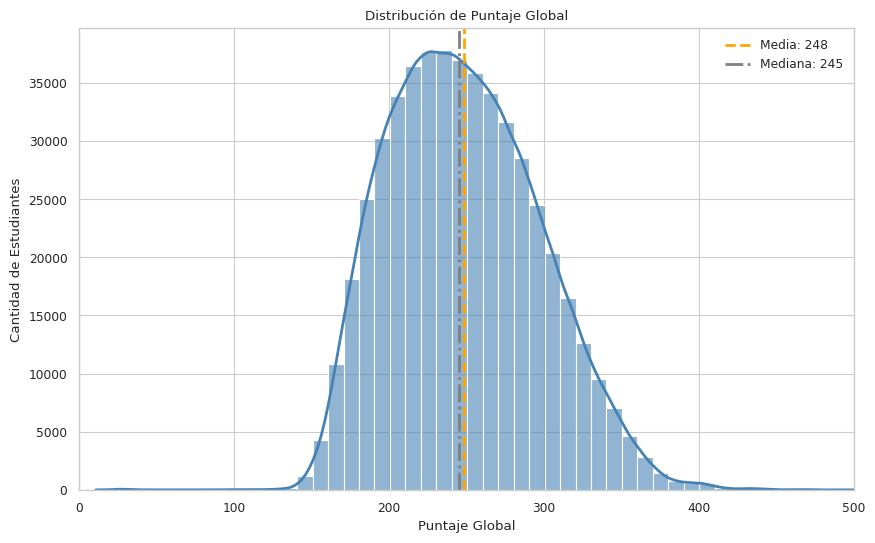

In [88]:
#PUNT_GLOBAL
plt.figure(figsize=(10,6))
sns.histplot(data=df, x = 'PUNT_GLOBAL', binwidth=10, kde=True, color='steelblue', edgecolor="white", alpha=0.6, line_kws={"linewidth":2})
plt.axvline(df['PUNT_GLOBAL'].mean(), color="orange", linestyle="--", label=f"Media: {df['PUNT_GLOBAL'].mean():.0f}", linewidth=2)
plt.axvline(df['PUNT_GLOBAL'].median(), color="grey", linestyle="-.", label=f"Mediana: {df['PUNT_GLOBAL'].median():.0f}", linewidth=2)
plt.title("Distribución de Puntaje Global")
plt.xlabel("Puntaje Global")
plt.ylabel("Cantidad de Estudiantes")
plt.xlim(0,500)
plt.legend(frameon=False)
plt.show()

In [89]:
#PUNT_GLOBAL
media = df['PUNT_GLOBAL'].mean()
mediana = df['PUNT_GLOBAL'].median()
desviacion = df['PUNT_GLOBAL'].std()
min = df['PUNT_GLOBAL'].min()
max = df['PUNT_GLOBAL'].max()
rango = max - min
q1 = df['PUNT_GLOBAL'].quantile(0.25)
q3 = df['PUNT_GLOBAL'].quantile(0.75)
asimetria = df['PUNT_GLOBAL'].skew()
kurtosis = df['PUNT_GLOBAL'].kurt()

print(f"""
Variable Objetivo: PUNT_GLOBAL

    Media: {media:.2f}
    Mediana: {mediana}
    Desviación: {desviacion:.2f}
    Rango: {rango}
    Quartil 1: {q1}
    Quartil 3: {q3}
    Asimetria: {asimetria:.2f}
    Kurtosis: {kurtosis:.2f}
""")


Variable Objetivo: PUNT_GLOBAL

    Media: 248.39
    Mediana: 245.0
    Desviación: 48.60
    Rango: 489
    Quartil 1: 211.0
    Quartil 3: 282.0
    Asimetria: 0.34
    Kurtosis: -0.20



En este caso la variable PUNT_GLOBAL es continua, sin embargo, para el experimento planteado será discretizada, con el objetivo de clasificar si el estudiante tendrá un puntaje bajo medio o alto. Debido a que el ICFES no clasifica sus puntajes los rangos van a ser definidos mediente los resultados estadisticos. Para ello se tomarán como nivel Bajo aquellos que estén por debajo de la media en una desviación estandar. Y para el nivel alto se tomará aquellos que se encuentran una desviacion estandar por encima.

In [90]:
#Creacion de la variable objetivo de clasificación NIVEL_GLOBAL
bins = (0, media-desviacion, media+desviacion, 500)
df['NIVEL_GLOBAL'] = pd.cut(df['PUNT_GLOBAL'], bins=bins, labels=["BAJO", "MEDIO", "ALTO"], include_lowest=True)
df['NIVEL_GLOBAL'].value_counts(normalize=True)

,proportion
NIVEL_GLOBAL,
MEDIO,0.656207
ALTO,0.172524
BAJO,0.171270


In [91]:
df = df.drop(columns='PUNT_GLOBAL')

Al realizar la comprobación de los nuevos valores de la variable objetivo tenemos que la clase MEDIO representa un 65% de los registros, mientras que las 2 restantes son aproximadamente un 17% cada una. Esto implica un desbalance bastante grande, lo que puede conllevar a que el modelo se centre simplemente en trabajar con la clase MEDIO.

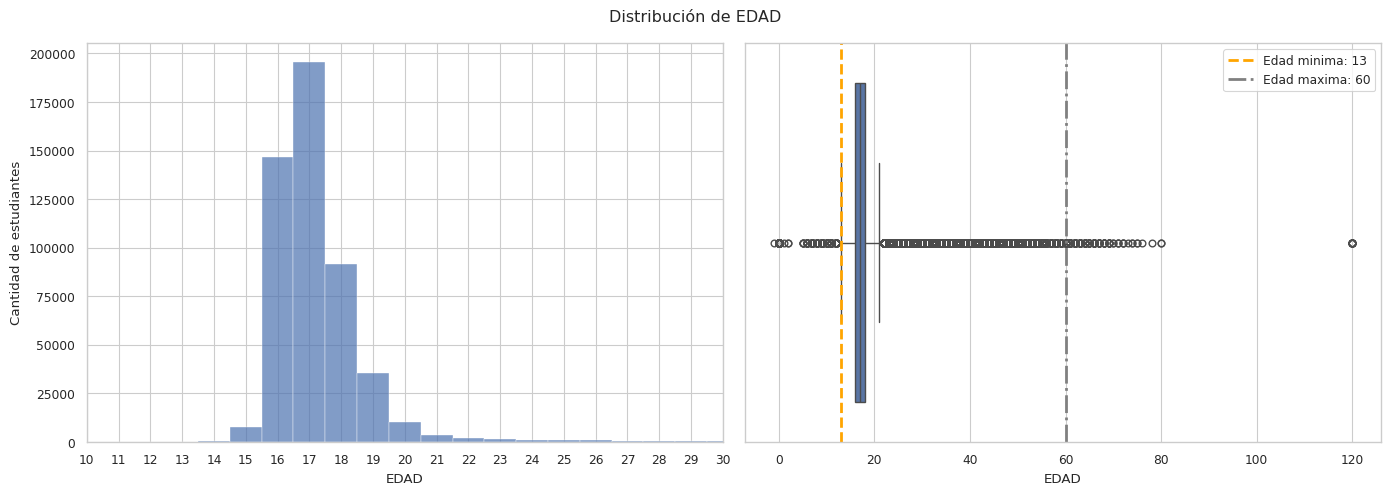

In [92]:
#EDAD
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x='ESTU_EDAD', discrete=True, ax=ax1, alpha=0.7)
ax1.set_xlim(10,30)
ax1.set_xticks(range(10,31,1))
ax1.set_xlabel("EDAD")
ax1.set_ylabel("Cantidad de estudiantes")

sns.boxplot(data=df, x='ESTU_EDAD', ax=ax2)
ax2.set_xlabel("EDAD")
ax2.axvline(x=13, color="orange", linewidth=2, linestyle="--", label="Edad minima: 13")
ax2.axvline(x=60, color="grey", linewidth=2, linestyle="-.", label="Edad maxima: 60")

fig.suptitle("Distribución de EDAD")
plt.tight_layout()
plt.legend()
plt.show()

In [93]:
df.loc[(df['ESTU_EDAD']<13) | (df['ESTU_EDAD']>60), 'ESTU_EDAD'] = np.nan

Al observar de forma detallada la variable ESTU_EDAD se conluye que existen 427 valores que según las reglas de calidad no son validos. Por lo tanto serán transformados a valores nulos para posteriormente tratarlos.

In [94]:
perfil = []

for col in df.select_dtypes(exclude='number').columns.tolist():
    fila = {
        "Atributo":col,
        "# Categorias": df[col].nunique(),
        "Moda": df[col].value_counts(normalize=True, dropna=False).index[0],
        "Categoria menos frecuente": df[col].value_counts(normalize=True, dropna=True).sort_values(ascending=True).index[0],
        "% Nulos": f"{df[col].isna().mean():.2f} %",
        "Tiene falsos nulos": ("No sabe" in df[col].unique().tolist()) | ("No Aplica" in df[col].unique().tolist())

    }
    perfil.append(fila)

In [95]:
df_perfil_categoricas = pd.DataFrame(perfil)
df_perfil_categoricas

,Atributo,# Categorias,Moda,Categoria menos frecuente,% Nulos,Tiene falsos nulos
0,ESTU_GENERO,2,F,M,0.00 %,False
1,ESTU_TIENEETNIA,2,No,Si,0.01 %,False
2,FAMI_ESTRATOVIVIENDA,7,Estrato 2,Estrato 6,0.03 %,False
3,FAMI_PERSONASHOGAR,5,3 a 4,9 o más,0.03 %,False
4,FAMI_CUARTOSHOGAR,6,Tres,Seis o mas,0.03 %,False
5,FAMI_EDUCACIONPADRE,12,Secundaria (Bachillerato) completa,No Aplica,0.03 %,True
6,FAMI_EDUCACIONMADRE,12,Secundaria (Bachillerato) completa,No Aplica,0.03 %,True
7,FAMI_TRABAJOLABORPADRE,12,Es dueño de un negocio pequeño (tiene pocos em...,Pensionado,0.04 %,True
8,FAMI_TRABAJOLABORMADRE,12,"Trabaja en el hogar, no trabaja o estudia",Pensionado,0.03 %,True
9,FAMI_TIENEINTERNET,2,Si,No,0.03 %,False


El analisis estadistico permite observar como algunas variables presentan valoers fuera de las reglas de calidad. Además de algunos valores que pueden considerarse como falsos nulos, los cuales deberían ser tratados.

### 4. Partición de los datos

In [96]:
from sklearn.model_selection import train_test_split
X = df.drop(columns='NIVEL_GLOBAL')
y = df['NIVEL_GLOBAL']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

### 5. Analisis de correlaciones

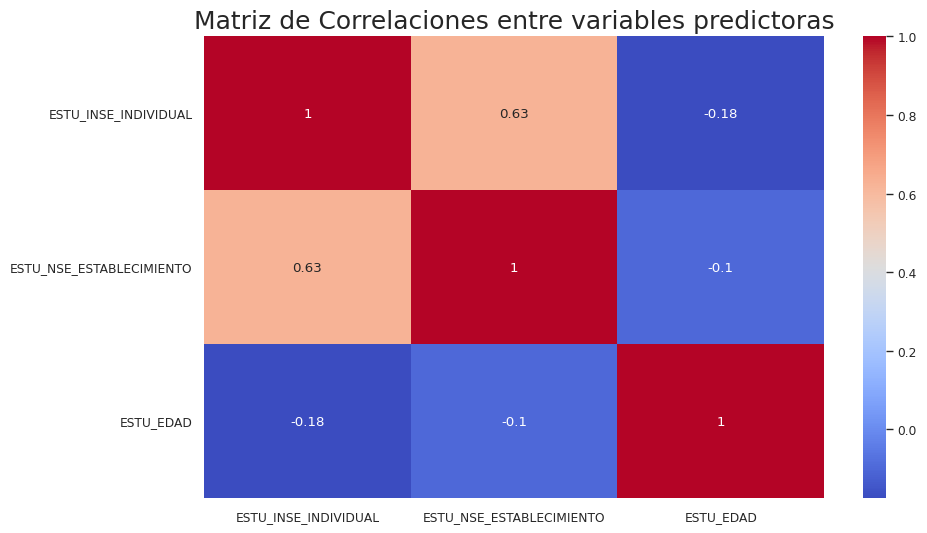

In [97]:
#Correlaciones entre variables predictoras numericas
var_numericas = X_train.select_dtypes(include="number")
matriz_corr_numericas = var_numericas.corr()

plt.figure(figsize=(10,6))
sns.heatmap(matriz_corr_numericas, annot=True, cmap="coolwarm")
plt.title("Matriz de Correlaciones entre variables predictoras", fontdict={'size':18})
plt.show()

### 6. Limpieza de valores nulos

In [98]:
col_numericas = X_train.select_dtypes(include="number").columns.tolist()
col_categoricas = X_train.select_dtypes(exclude="number").columns.tolist()

X_train = X_train.fillna(np.nan)
X_test = X_test.fillna(np.nan)

In [99]:
#Registros con alta cantidad de valores nulos
filas_validas_train = (X_train.isna().mean(axis=1) <= 0.15)
print(filas_validas_train.sum())
X_train = X_train[filas_validas_train]
y_train = y_train[filas_validas_train]
filas_validas_test = (X_test.isna().mean(axis=1) <= 0.15)
X_test = X_test[filas_validas_test]
y_test = y_test[filas_validas_test]

342519


In [100]:
X_train.shape

(342519, 34)

In [101]:
#Atributos con alta cantidad de nulos
print(f"Cantidad de atributos con 15% o más nulos: {(X_train.isna().mean() >= 0.15).sum()}")

Cantidad de atributos con 15% o más nulos: 0


In [102]:
from sklearn.impute import SimpleImputer
imputer_numericas = SimpleImputer(strategy="mean").set_output(transform="pandas")
imputer_categoricas = SimpleImputer(strategy="most_frequent").set_output(transform="pandas")

X_train[col_numericas] = imputer_numericas.fit_transform(X_train[col_numericas])
X_train[col_categoricas] = imputer_categoricas.fit_transform(X_train[col_categoricas])

X_test[col_numericas] = imputer_numericas.transform(X_test[col_numericas])
X_test[col_categoricas] = imputer_categoricas.transform(X_test[col_categoricas])

print(X_train.isna().sum().sum(), X_test.isna().sum().sum())

0 0


### 7. Codificación

In [103]:
col_ordinales = ['FAMI_ESTRATOVIVIENDA', 'FAMI_PERSONASHOGAR', 'ESTU_DEDICACIONLECTURADIARIA', 'FAMI_CUARTOSHOGAR', 'FAMI_NUMLIBROS', 'FAMI_COMELECHEDERIVADOS', 'FAMI_COMECARNEPESCADOHUEVO', 'FAMI_COMECEREALFRUTOSLEGUMBRE', 'FAMI_SITUACIONECONOMICA', 'ESTU_DEDICACIONINTERNET', 'ESTU_HORASSEMANATRABAJA']

orden_categorias = [
    ["Sin Estrato", "Estrato 1", "Estrato 2", "Estrato 3", "Estrato 4", "Estrato 5", "Estrato 6"],
    ["1 a 2", "3 a 4", "5 a 6", "7 a 8", "9 o más"],
    ["No leo por entretenimiento", "30 minutos o menos", "Entre 30 y 60 minutos", "Entre 1 y 2 horas", "Más de 2 horas"],
    ["Uno", "Dos", "Tres", "Cuatro", "Cinco", "Seis o mas"],
    ["0 A 10 LIBROS", "11 A 25 LIBROS", "26 A 100 LIBROS", "MÁS DE 100 LIBROS"],
    ["Nunca o rara vez comemos eso", "1 o 2 veces por semana","3 a 5 veces por semana",	"Todos o casi todos los días"],
    ["Nunca o rara vez comemos eso", "1 o 2 veces por semana","3 a 5 veces por semana",	"Todos o casi todos los días"],
    ["Nunca o rara vez comemos eso", "1 o 2 veces por semana","3 a 5 veces por semana",	"Todos o casi todos los días"],
    ['Peor', 'Igual', 'Mejor'],
    ["No Navega Internet", "30 minutos o menos", "Entre 30 y 60 minutos", "Entre 1 y 3 horas", "Más de 3 horas"],
	["0", "Menos de 10 horas", "Entre 11 y 20 horas", "Entre 21 y 30 horas", "Más de 30 horas"]
]


In [104]:
X_test.head()

,ESTU_GENERO,ESTU_TIENEETNIA,FAMI_ESTRATOVIVIENDA,FAMI_PERSONASHOGAR,FAMI_CUARTOSHOGAR,FAMI_EDUCACIONPADRE,FAMI_EDUCACIONMADRE,FAMI_TRABAJOLABORPADRE,FAMI_TRABAJOLABORMADRE,FAMI_TIENEINTERNET,...,ESTU_HORASSEMANATRABAJA,ESTU_TIPOREMUNERACION,COLE_NATURALEZA,COLE_CARACTER,COLE_AREA_UBICACION,COLE_JORNADA,COLE_DEPTO_UBICACION,ESTU_INSE_INDIVIDUAL,ESTU_NSE_ESTABLECIMIENTO,ESTU_EDAD
450123,F,No,Estrato 1,3 a 4,Tres,Primaria incompleta,Primaria incompleta,"Es agricultor, pesquero o jornalero","Trabaja en el hogar, no trabaja o estudia",Si,...,0,No,OFICIAL,ACADÉMICO,RURAL,MAÑANA,ANTIOQUIA,42.537479,1.0,18.0
441541,F,No,Estrato 2,7 a 8,Tres,Primaria completa,Secundaria (Bachillerato) completa,Es vendedor o trabaja en atención al público,"Trabaja en el hogar, no trabaja o estudia",Si,...,0,No,OFICIAL,TÉCNICO/ACADÉMICO,URBANO,MAÑANA,SANTANDER,51.984154,3.0,17.0
359338,F,No,Estrato 3,5 a 6,Tres,Postgrado,Educación profesional completa,"Trabaja como profesional (por ejemplo médico, ...","Trabaja como profesional (por ejemplo médico, ...",Si,...,Entre 21 y 30 horas,No,OFICIAL,TÉCNICO/ACADÉMICO,URBANO,UNICA,CORDOBA,67.297243,3.0,17.0
429927,M,No,Estrato 3,5 a 6,Cinco,Técnica o tecnológica completa,Educación profesional completa,"Trabaja en el hogar, no trabaja o estudia","Trabaja como profesional (por ejemplo médico, ...",Si,...,0,No,NO OFICIAL,ACADÉMICO,URBANO,COMPLETA,ANTIOQUIA,63.903094,4.0,17.0
382033,F,No,Estrato 4,3 a 4,Tres,Secundaria (Bachillerato) completa,Educación profesional completa,Pensionado,Pensionado,Si,...,0,No,NO OFICIAL,ACADÉMICO,URBANO,COMPLETA,BOGOTÁ,66.384255,4.0,18.0


In [105]:
col_nominales = ['ESTU_GENERO', 'ESTU_TIENEETNIA',
                'FAMI_TIENEINTERNET', 'FAMI_TIENESERVICIOTV', 'FAMI_TIENECOMPUTADOR',
                'FAMI_TIENELAVADORA', 'FAMI_TIENEHORNOMICROOGAS', 'FAMI_TIENEAUTOMOVIL',
                'FAMI_TIENEMOTOCICLETA', 'FAMI_TIENECONSOLAVIDEOJUEGOS',
                'COLE_NATURALEZA', 'COLE_AREA_UBICACION', 'FAMI_TRABAJOLABORPADRE', 'FAMI_TRABAJOLABORMADRE',
                 'FAMI_EDUCACIONPADRE', 'FAMI_EDUCACIONMADRE',
                 'ESTU_TIPOREMUNERACION', 'COLE_CARACTER', 'COLE_JORNADA',
                 'COLE_DEPTO_UBICACION']

In [45]:
print(X_train.shape, X_test.shape)

(342519, 34) (146754, 34)


8. Balanceo

In [46]:
#codificacion de la variable objetivo
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)

y_test_enc = le.transform(y_test)

print(le.classes_)

['ALTO' 'BAJO' 'MEDIO']


Luego del balanceo tenemos que la cantidad de registros para train y para test es muy similar. Esto se debe a la naturaleza del metodo de balanceo implementado, el cual elimina registros hasta balancear la variable objetivo

In [106]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (OrdinalEncoder, OneHotEncoder,
                                   MinMaxScaler, LabelEncoder)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, GridSearchCV)

from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
prep_ordinales = Pipeline([
    ('imputar', SimpleImputer(strategy='most_frequent')),
    ('codificar', OrdinalEncoder(categories=orden_categorias)),
])

prep_onehot = Pipeline([
    ('imputar', SimpleImputer(strategy='most_frequent')),
    ('codificar', OneHotEncoder(drop='if_binary', handle_unknown='ignore',
                                sparse_output=False)),
])

prep_numericas = Pipeline([
    ('imputar', SimpleImputer(strategy='mean')),
    ('escalar', MinMaxScaler()),
])


preprocesamiento = ColumnTransformer([
    ('ordinales', prep_ordinales, col_ordinales),
    ('onehot', prep_onehot, col_nominales),
    ('numericas', prep_numericas, col_numericas),
])

def armar_pipeline(modelo):
    return ImbPipeline([
        ('balanceo', RandomUnderSampler(random_state=42)),
        ('preparacion', clone(preprocesamiento)),
        ('modelo', modelo),
    ])

In [222]:
from sklearn.linear_model import LogisticRegression


logistic_model = LogisticRegression(max_iter=1000, random_state=42)

pipeline_logistic = armar_pipeline(logistic_model)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


resultados = cross_validate(pipeline_logistic, X_train, y_train_enc,
                            cv=cv, scoring='f1_macro',
                            return_train_score=True, n_jobs=-1)

print("F1 por fold:", resultados['test_score'].round(4))
print("CV Mean:", resultados['test_score'].mean().round(4))
print("CV Std:", resultados['test_score'].std().round(4))
print("F1 en train:", resultados['train_score'].mean().round(4))
print("Tiempo promedio por fold (s):", resultados['fit_time'].mean().round(1))

F1 por fold: [0.5241 0.5237 0.5265 0.5245 0.5259]
CV Mean: 0.5249
CV Std: 0.0011
F1 en train: 0.5254
Tiempo promedio por fold (s): 101.0


In [223]:
from sklearn.svm import LinearSVC

LinearSVC_model = LinearSVC(random_state=42)
pipeline_SVC = armar_pipeline(LinearSVC_model)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados = cross_validate(pipeline_SVC, X_train, y_train_enc,
                            cv=cv, scoring='f1_macro',
                            return_train_score=True, n_jobs=-1)

print("F1 por fold:", resultados['test_score'].round(4))
print("CV Mean:", resultados['test_score'].mean().round(4))
print("CV Std:", resultados['test_score'].std().round(4))
print("F1 en train:", resultados['train_score'].mean().round(4))
print("Tiempo promedio por fold (s):", resultados['fit_time'].mean().round(1))

F1 por fold: [0.4821 0.4817 0.4852 0.483  0.4851]
CV Mean: 0.4834
CV Std: 0.0015
F1 en train: 0.4838
Tiempo promedio por fold (s): 26.0


In [226]:
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(random_state=42, max_iter=1000, early_stopping=True)
pipeline_mlp = armar_pipeline(mlp_model)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados = cross_validate(pipeline_mlp, X_train, y_train_enc, cv=cv, scoring='f1_macro', return_train_score=True, n_jobs=-1)
print(f"F1 por fold: {resultados['test_score'].round(4)}")
print(f"CV Mean: {resultados['test_score'].mean().round(4)}")
print(f"CV Std: {resultados['test_score'].std().round(4)}")
print(f"F1 en train: {resultados['train_score'].mean().round(4)}")
print(f"Tiempo promedio por fold (s): {resultados['fit_time'].mean().round(1)}")

F1 por fold: [0.5436 0.5299 0.5409 0.5234 0.5343]
CV Mean: 0.5344
CV Std: 0.0073
F1 en train: 0.545
Tiempo promedio por fold (s): 59.7


In [227]:
from sklearn.tree import DecisionTreeClassifier

arbol_model = DecisionTreeClassifier(max_depth=10, random_state=42)
pipeline_arbol = armar_pipeline(arbol_model)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados = cross_validate(pipeline_arbol, X_train, y_train_enc, cv=cv, scoring="f1_macro", return_train_score=True, n_jobs=-1)
print(f"F1 por fold: {resultados['test_score'].round(4)}")
print(f"CV Mean: {resultados['test_score'].mean().round(4)}")
print(f"CV Std: {resultados['test_score'].std().round(4)}")
print(f"F1 en train: {resultados['train_score'].mean().round(4)}")
print(f"Tiempo promedio por fold (s): {resultados['fit_time'].mean().round(1)}")

F1 por fold: [0.4891 0.4703 0.4846 0.5019 0.5017]
CV Mean: 0.4895
CV Std: 0.0118
F1 en train: 0.5007
Tiempo promedio por fold (s): 16.9


In [228]:
from sklearn.naive_bayes import GaussianNB

naive_model = GaussianNB()
pipeline_naive = armar_pipeline(naive_model)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados = cross_validate(pipeline_naive, X_train, y_train_enc, scoring="f1_macro", return_train_score=True, n_jobs=-1)

print(f"F1 por fold: {resultados['test_score'].round(4)}")
print(f"CV Mean: {resultados['test_score'].mean().round(4)}")
print(f"CV Std: {resultados['test_score'].std().round(4)}")
print(f"F1 en train: {resultados['train_score'].mean().round(4)}")
print(f"Tiempo promedio por fold (s): {resultados['fit_time'].mean().round(1)}")

F1 por fold: [0.4335 0.4326 0.4358 0.4291 0.4266]
CV Mean: 0.4315
CV Std: 0.0033
F1 en train: 0.4318
Tiempo promedio por fold (s): 7.8


MODELOS DE ENSAMBLES

In [229]:
from sklearn.ensemble import VotingClassifier

voting_model = VotingClassifier(
    estimators=[
        ('mlp', mlp_model),
        ('logistica', logistic_model),
        ('arbol', arbol_model),
    ],
    voting='soft'
)
pipeline_voting = armar_pipeline(voting_model)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados = cross_validate(pipeline_voting, X_train, y_train_enc,
                            cv=cv, scoring='f1_macro',
                            return_train_score=True, n_jobs=-1)

print(f"F1 por fold: {resultados['test_score'].round(4)}")
print(f"CV Mean: {resultados['test_score'].mean().round(4)}")
print(f"CV Std: {resultados['test_score'].std().round(4)}")
print(f"F1 en train: {resultados['train_score'].mean().round(4)}")
print(f"Tiempo promedio por fold (s): {resultados['fit_time'].mean().round(1)}")

F1 por fold: [0.5341 0.5267 0.5356 0.5247 0.5309]
CV Mean: 0.5304
CV Std: 0.0042
F1 en train: 0.5393
Tiempo promedio por fold (s): 137.8


In [230]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    n_jobs=-1,
    random_state=42
)
pipeline_rf = armar_pipeline(rf_model)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados = cross_validate(pipeline_rf, X_train, y_train_enc,
                            cv=cv, scoring='f1_macro',
                            return_train_score=True)

print(f"F1 por fold: {resultados['test_score'].round(4)}")
print(f"CV Mean: {resultados['test_score'].mean().round(4)}")
print(f"CV Std: {resultados['test_score'].std().round(4)}")
print(f"F1 en train: {resultados['train_score'].mean().round(4)}")
print(f"Tiempo promedio por fold (s): {resultados['fit_time'].mean().round(1)}")

F1 por fold: [0.4985 0.4971 0.501  0.4982 0.4957]
CV Mean: 0.4981
CV Std: 0.0018
F1 en train: 0.5522
Tiempo promedio por fold (s): 36.9


In [48]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    tree_method='hist',
    n_jobs=-1,
    random_state=42
)

pipeline_xgb = armar_pipeline(xgb_model)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados = cross_validate(pipeline_xgb, X_train, y_train_enc,
                            cv=cv, scoring='f1_macro',
                            return_train_score=True)

print(f"F1 por fold: {resultados['test_score'].round(4)}")
print(f"CV Mean: {resultados['test_score'].mean().round(4)}")
print(f"CV Std: {resultados['test_score'].std().round(4)}")
print(f"F1 en train: {resultados['train_score'].mean().round(4)}")
print(f"Tiempo promedio por fold (s): {resultados['fit_time'].mean().round(1)}")

F1 por fold: [0.5366 0.5354 0.5387 0.5349 0.5369]
CV Mean: 0.5365
CV Std: 0.0013
F1 en train: 0.5555
Tiempo promedio por fold (s): 32.7


### Ajuste de Hiperparametros

In [51]:
param_grid = {
    'modelo__max_depth': [4, 6, 8],
    'modelo__learning_rate': [0.05, 0.1],
    'modelo__n_estimators': [200, 400],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(pipeline_xgb, param_grid,
                    cv=cv, scoring='f1_macro',
                    return_train_score=True,
                    verbose=2)

grid.fit(X_train, y_train_enc)

print("Mejores hiperparámetros:", grid.best_params_)
print("Mejor CV Mean:", round(grid.best_score_, 4))

tabla = pd.DataFrame(grid.cv_results_)[
    ['params', 'mean_test_score', 'std_test_score', 'mean_train_score']
].sort_values('mean_test_score', ascending=False)
print(tabla.head(12))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV] END modelo__learning_rate=0.05, modelo__max_depth=4, modelo__n_estimators=200; total time=  31.7s
[CV] END modelo__learning_rate=0.05, modelo__max_depth=4, modelo__n_estimators=200; total time=  31.1s
[CV] END modelo__learning_rate=0.05, modelo__max_depth=4, modelo__n_estimators=200; total time=  29.7s
[CV] END modelo__learning_rate=0.05, modelo__max_depth=4, modelo__n_estimators=200; total time=  29.2s
[CV] END modelo__learning_rate=0.05, modelo__max_depth=4, modelo__n_estimators=200; total time=  30.1s
[CV] END modelo__learning_rate=0.05, modelo__max_depth=4, modelo__n_estimators=400; total time=  56.3s
[CV] END modelo__learning_rate=0.05, modelo__max_depth=4, modelo__n_estimators=400; total time=  52.6s
[CV] END modelo__learning_rate=0.05, modelo__max_depth=4, modelo__n_estimators=400; total time=  55.6s
[CV] END modelo__learning_rate=0.05, modelo__max_depth=4, modelo__n_estimators=400; total time=  51.1s
[CV] END mod

In [56]:
X_test.shape

(146754, 34)

Accuracy: 0.5539
Precision (macro): 0.5374
Recall (macro): 0.6464
F1 (macro): 0.5439
              precision    recall  f1-score   support

        ALTO     0.4147    0.7527    0.5348     25451
        BAJO     0.3996    0.7307    0.5167     24859
       MEDIO     0.7978    0.4558    0.5801     96444

    accuracy                         0.5539    146754
   macro avg     0.5374    0.6464    0.5439    146754
weighted avg     0.6639    0.5539    0.5615    146754



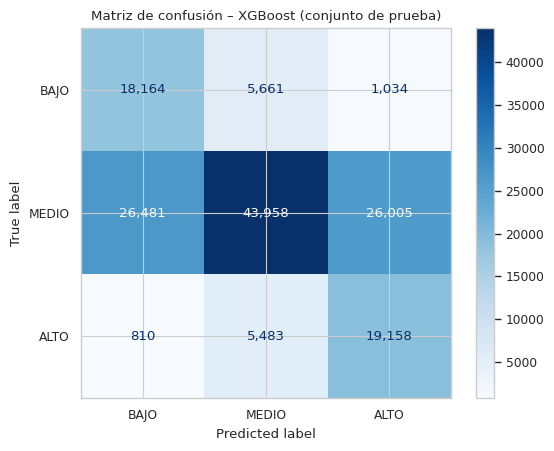

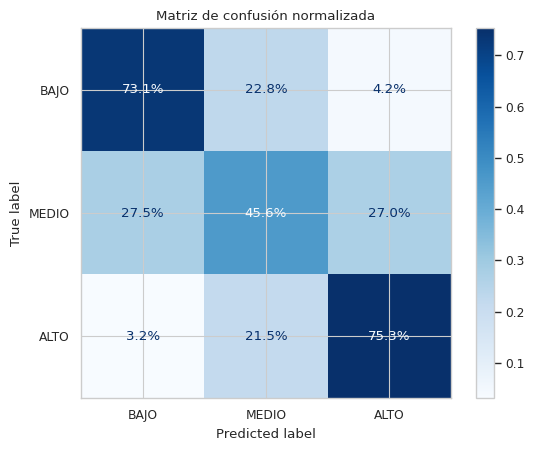

In [54]:
from sklearn.metrics import (classification_report, accuracy_score, f1_score,
                             precision_score, recall_score, ConfusionMatrixDisplay)

modelo_final = grid.best_estimator_


y_pred = modelo_final.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test_enc, y_pred), 4))
print("Precision (macro):", round(precision_score(y_test_enc, y_pred, average='macro'), 4))
print("Recall (macro):", round(recall_score(y_test_enc, y_pred, average='macro'), 4))
print("F1 (macro):", round(f1_score(y_test_enc, y_pred, average='macro'), 4))

print(classification_report(y_test_enc, y_pred, target_names=le.classes_, digits=4))


orden = [1, 2, 0]
nombres = ['BAJO', 'MEDIO', 'ALTO']

ConfusionMatrixDisplay.from_predictions(y_test_enc, y_pred, labels=orden,
                                        display_labels=nombres, cmap='Blues',
                                        values_format=',')
plt.title('Matriz de confusión – XGBoost (conjunto de prueba)')
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test_enc, y_pred, labels=orden,
                                        display_labels=nombres, cmap='Blues',
                                        normalize='true', values_format='.1%')
plt.title('Matriz de confusión normalizada')
plt.show()

In [62]:
import joblib

ruta = '/content/drive/MyDrive/PROYECTO ICFES/'
joblib.dump(modelo_final, ruta + 'modelofinal_saber11.pkl')
joblib.dump(le, ruta + 'label_encoder.pkl')

['/content/drive/MyDrive/PROYECTO ICFES/label_encoder.pkl']

In [64]:
#Nuevos estudiantes
ruta = '/content/drive/MyDrive/PROYECTO ICFES/'
modelo_cargado = joblib.load(ruta + 'modelofinal_saber11.pkl')
le_cargado = joblib.load(ruta + 'label_encoder.pkl')

base = {
    'ESTU_GENERO': 'F', 'ESTU_TIENEETNIA': 'No', 'ESTU_EDAD': 17.0,
    'FAMI_PERSONASHOGAR': '3 a 4', 'FAMI_SITUACIONECONOMICA': 'Igual',
    'FAMI_TIENESERVICIOTV': 'Si', 'FAMI_TIENELAVADORA': 'Si',
    'FAMI_COMELECHEDERIVADOS': '3 a 5 veces por semana',
    'FAMI_COMECARNEPESCADOHUEVO': 'Todos o casi todos los días',
    'FAMI_COMECEREALFRUTOSLEGUMBRE': '3 a 5 veces por semana',
    'ESTU_DEDICACIONINTERNET': 'Entre 1 y 3 horas',
    'ESTU_HORASSEMANATRABAJA': '0', 'ESTU_TIPOREMUNERACION': 'No',
    'COLE_CARACTER': 'ACADÉMICO',
}

estudiante_1 = {**base,
    'FAMI_ESTRATOVIVIENDA': 'Estrato 1', 'FAMI_CUARTOSHOGAR': 'Dos',
    'FAMI_EDUCACIONPADRE': 'Primaria incompleta', 'FAMI_EDUCACIONMADRE': 'Primaria completa',
    'FAMI_TRABAJOLABORPADRE': 'Es agricultor, pesquero o jornalero',
    'FAMI_TRABAJOLABORMADRE': 'Trabaja en el hogar, no trabaja o estudia',
    'FAMI_TIENEINTERNET': 'No', 'FAMI_TIENECOMPUTADOR': 'No', 'FAMI_TIENEHORNOMICROOGAS': 'No',
    'FAMI_TIENEAUTOMOVIL': 'No', 'FAMI_TIENEMOTOCICLETA': 'Si', 'FAMI_TIENECONSOLAVIDEOJUEGOS': 'No',
    'FAMI_NUMLIBROS': '0 A 10 LIBROS', 'ESTU_DEDICACIONLECTURADIARIA': 'No leo por entretenimiento',
    'ESTU_DEDICACIONINTERNET': 'No Navega Internet',
    'ESTU_HORASSEMANATRABAJA': 'Entre 11 y 20 horas', 'ESTU_TIPOREMUNERACION': 'Si, en efectivo',
    'COLE_NATURALEZA': 'OFICIAL', 'COLE_AREA_UBICACION': 'RURAL', 'COLE_JORNADA': 'MAÑANA',
    'COLE_DEPTO_UBICACION': 'CHOCO', 'ESTU_INSE_INDIVIDUAL': 35.0, 'ESTU_NSE_ESTABLECIMIENTO': 1.0,
}

estudiante_2 = {**base,
    'FAMI_ESTRATOVIVIENDA': 'Estrato 2', 'FAMI_CUARTOSHOGAR': 'Tres',
    'FAMI_EDUCACIONPADRE': 'Secundaria (Bachillerato) completa',
    'FAMI_EDUCACIONMADRE': 'Técnica o tecnológica completa',
    'FAMI_TRABAJOLABORPADRE': 'Trabaja por cuenta propia (por ejemplo plomero, electricista)',
    'FAMI_TRABAJOLABORMADRE': 'Es vendedor o trabaja en atención al público',
    'FAMI_TIENEINTERNET': 'Si', 'FAMI_TIENECOMPUTADOR': 'Si', 'FAMI_TIENEHORNOMICROOGAS': 'No',
    'FAMI_TIENEAUTOMOVIL': 'No', 'FAMI_TIENEMOTOCICLETA': 'No', 'FAMI_TIENECONSOLAVIDEOJUEGOS': 'No',
    'FAMI_NUMLIBROS': '11 A 25 LIBROS', 'ESTU_DEDICACIONLECTURADIARIA': '30 minutos o menos',
    'COLE_NATURALEZA': 'OFICIAL', 'COLE_AREA_UBICACION': 'URBANO', 'COLE_JORNADA': 'TARDE',
    'COLE_DEPTO_UBICACION': 'ANTIOQUIA', 'ESTU_INSE_INDIVIDUAL': 51.0, 'ESTU_NSE_ESTABLECIMIENTO': 2.0,
}

estudiante_3 = {**base,
    'FAMI_ESTRATOVIVIENDA': 'Estrato 5', 'FAMI_CUARTOSHOGAR': 'Cuatro',
    'FAMI_EDUCACIONPADRE': 'Postgrado', 'FAMI_EDUCACIONMADRE': 'Educación profesional completa',
    'FAMI_TRABAJOLABORPADRE': 'Trabaja como profesional (por ejemplo médico, abogado, ingeniero)',
    'FAMI_TRABAJOLABORMADRE': 'Trabaja como profesional (por ejemplo médico, abogado, ingeniero)',
    'FAMI_TIENEINTERNET': 'Si', 'FAMI_TIENECOMPUTADOR': 'Si', 'FAMI_TIENEHORNOMICROOGAS': 'Si',
    'FAMI_TIENEAUTOMOVIL': 'Si', 'FAMI_TIENEMOTOCICLETA': 'No', 'FAMI_TIENECONSOLAVIDEOJUEGOS': 'Si',
    'FAMI_NUMLIBROS': 'MÁS DE 100 LIBROS', 'ESTU_DEDICACIONLECTURADIARIA': 'Entre 1 y 2 horas',
    'COLE_NATURALEZA': 'NO OFICIAL', 'COLE_AREA_UBICACION': 'URBANO', 'COLE_JORNADA': 'COMPLETA',
    'COLE_DEPTO_UBICACION': 'BOGOTÁ', 'ESTU_INSE_INDIVIDUAL': 72.0, 'ESTU_NSE_ESTABLECIMIENTO': 4.0,
}

nuevos = pd.DataFrame([estudiante_1, estudiante_2, estudiante_3],
                      index=['Estudiante 1',
                             'Estudiante 2',
                             'Estudiante 3'])

nuevos = nuevos[modelo_cargado.named_steps['preparacion'].feature_names_in_]

pred = modelo_cargado.predict(nuevos)
proba = modelo_cargado.predict_proba(nuevos)

resultado = pd.DataFrame(proba, columns=[f'Prob. {c}' for c in le_cargado.classes_], index=nuevos.index).round(3)
resultado.insert(0, 'Predicción', le_cargado.inverse_transform(pred))
display(resultado)

,Predicción,Prob. ALTO,Prob. BAJO,Prob. MEDIO
Estudiante 1,BAJO,0.013,0.552,0.434
Estudiante 2,MEDIO,0.338,0.145,0.517
Estudiante 3,ALTO,0.963,0.001,0.037


,Nivel real,Nivel predicho
243937,BAJO,MEDIO
258069,MEDIO,ALTO
345799,BAJO,MEDIO
256804,MEDIO,MEDIO
224356,MEDIO,ALTO


In [108]:
import sys, sklearn, xgboost, imblearn, pandas, numpy, joblib
contenido = f"""streamlit
scikit-learn=={sklearn.__version__}
xgboost=={xgboost.__version__}
imbalanced-learn=={imblearn.__version__}
pandas=={pandas.__version__}
numpy=={numpy.__version__}
joblib=={joblib.__version__}
"""

with open(ruta + 'requirements.txt', 'w') as f:
    f.write(contenido)

print(contenido)
print("Versión de Python:", sys.version)

streamlit
scikit-learn==1.6.1
xgboost==3.4.1
imbalanced-learn==0.14.2
pandas==2.2.3
numpy==2.3.5
joblib==1.6.0

Versión de Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
